In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import logging

# matplotlibのフォントマネージャーのログレベルを「ERROR」以上に引き上げる
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# グラフの描画スタイル設定
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Hiragino Sans", "Meiryo", "Arial"]

In [10]:
train_df = pd.read_csv("/content/train.csv")
test_df = pd.read_csv("/content/test.csv")
original_df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Original shape: {original_df.shape}")

# 先頭データの確認
display(train_df.head(3))

Train shape: (594194, 21)
Test shape: (6939, 12)
Original shape: (7043, 21)


,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.1,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.5,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.4,5841.35,No


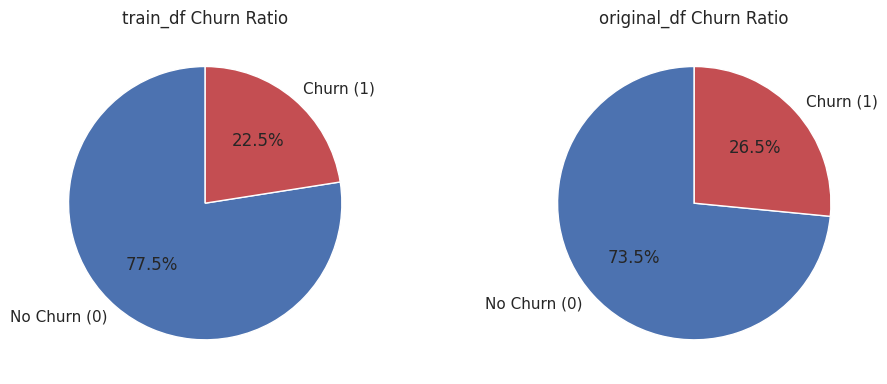

In [11]:
# Churn カラムの Yes/No を 1/0 にマッピングして確認
churn_map = {"Yes": 1, "No": 0}
train_churn_mapped = train_df["Churn"].map(churn_map)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# train_df の円グラフ
train_counts = train_churn_mapped.value_counts()
axes[0].pie(
    train_counts,
    labels=["No Churn (0)", "Churn (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4c72b0", "#c44e52"],
)
axes[0].set_title("train_df Churn Ratio")

# original_df の円グラフ
orig_churn_mapped = original_df["Churn"].map(churn_map)
orig_counts = orig_churn_mapped.value_counts()
axes[1].pie(
    orig_counts,
    labels=["No Churn (0)", "Churn (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4c72b0", "#c44e52"],
)
axes[1].set_title("original_df Churn Ratio")

plt.tight_layout()
plt.show()

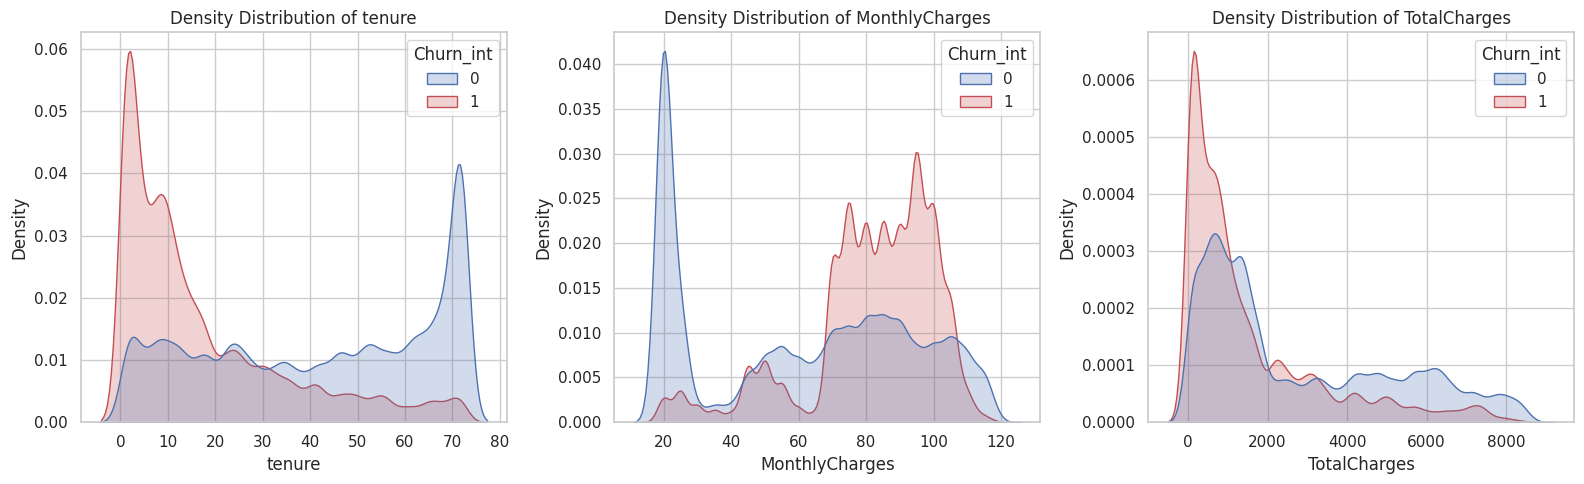

In [12]:
# 数値変数と Churn の確率密度関数 (KDE) 描画
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
features = ["tenure", "MonthlyCharges", "TotalCharges"]

for i, feature in enumerate(features):
    # TotalCharges は数値変換が必要な場合があるため安全に処理
    temp_df = train_df.copy()
    temp_df["Churn_int"] = temp_df["Churn"].map({"Yes": 1, "No": 0})
    temp_df[feature] = pd.to_numeric(temp_df[feature], errors="coerce")

    sns.kdeplot(
        data=temp_df,
        x=feature,
        hue="Churn_int",
        common_norm=False,
        fill=True,
        palette=["#4c72b0", "#c44e52"],
        ax=axes[i],
    )
    axes[i].set_title(f"Density Distribution of {feature}")

plt.tight_layout()
plt.show()

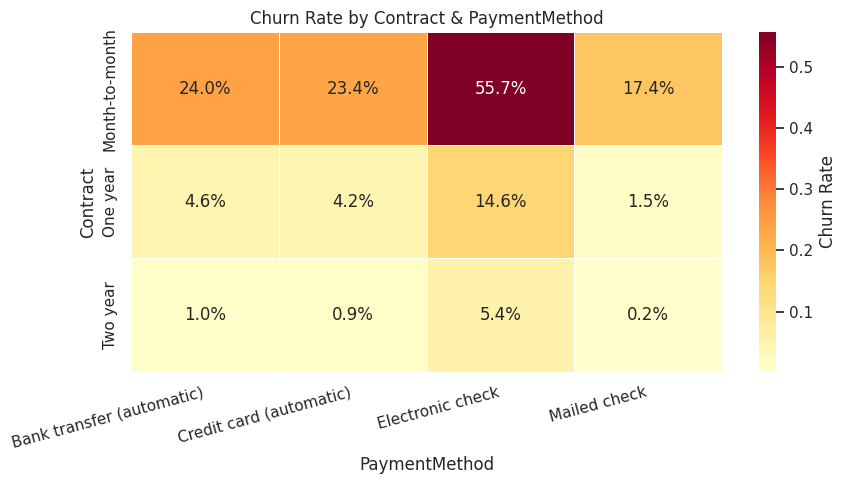

In [13]:
# クロス集計による離脱率の可視化
temp_df = train_df.copy()
temp_df["Churn_int"] = temp_df["Churn"].map({"Yes": 1, "No": 0})

pivot_churn = temp_df.pivot_table(
    index="Contract",
    columns="PaymentMethod",
    values="Churn_int",
    aggfunc="mean",
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    pivot_churn,
    annot=True,
    fmt=".1%",
    cmap="YlOrRd",
    cbar_kws={"label": "Churn Rate"},
    linewidths=0.5,
)
plt.title("Churn Rate by Contract & PaymentMethod")
plt.xlabel("PaymentMethod")
plt.ylabel("Contract")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()